

# DelaySense: Production-Grade Stacking Ensemble with Optuna Hyperparameter Optimization
### Late Delivery Risk Prediction using LightGBM, CatBoost (Native Categoricals) & XGBoost

This notebook implements an advanced, competition-grade ensemble pipeline to forecast supply chain delivery delays (`Late_delivery_risk`) using checkout-time data.
It features:
- **Strict Leakage-Free Preprocessing**: Eliminates post-dispatch target leakage (`Days for shipping (real)`, `Delivery Status`, `shipping date`).
- **Group-Aware Splitting**: Uses `GroupShuffleSplit` and 5-Fold `GroupKFold` on `Order Id` to strictly prevent item-level train/test contamination.
- **Optuna Bayesian Hyperparameter Optimization**: Automated Tree-structured Parzen Estimator (TPE) tuning for LightGBM and CatBoost.


In [16]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,

)

print("Dependencies and libraries loaded successfully!")


Dependencies and libraries loaded successfully!


## 1. Data Ingestion & Initial Exploration

In [17]:

df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")
df.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [18]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

## 2. Target Analysis & Data Leakage Prevention

In the DataCo dataset, `Late_delivery_risk` is determined by comparing `Days for shipping (real)` against `Days for shipment (scheduled)`.
- `Days for shipping (real)` and `shipping date (DateOrders)` represent **post-dispatch outcomes** unknown at checkout time.
- Including them produces artificial 99% accuracy via direct target leakage. Dropping them is mandatory for a valid predictive model.
- Notice below how scheduled days and late delivery risk strongly correlate with `Shipping Mode`.

In [20]:
real = df['Days for shipping (real)']
sched = df['Days for shipment (scheduled)']

print("Cross-tabulation: Late_delivery_risk vs (real > sched):")
print(pd.crosstab(df['Late_delivery_risk'], real > sched))

Cross-tabulation: Late_delivery_risk vs (real > sched):
col_0               False  True 
Late_delivery_risk              
0                   77119   4423
1                       0  98977


In [21]:
print("Scheduled days per Shipping Mode:")
print(df.groupby("Shipping Mode")["Days for shipment (scheduled)"].agg(["min", "max", "nunique"]))

print("\nLate Delivery Risk per Shipping Mode:")
print(df.groupby("Shipping Mode")["Late_delivery_risk"].agg(["mean", "count"]))

Scheduled days per Shipping Mode:
                min  max  nunique
Shipping Mode                    
First Class       1    1        1
Same Day          0    0        1
Second Class      2    2        1
Standard Class    4    4        1

Late Delivery Risk per Shipping Mode:
                    mean   count
Shipping Mode                   
First Class     0.953225   27814
Same Day        0.457430    9737
Second Class    0.766328   35216
Standard Class  0.380717  107752


In [22]:
print(f"Total line items (rows): {len(df)}")
print(f"Unique orders (Order Id): {df['Order Id'].nunique()}")
print(f"Average items per order: {len(df) / df['Order Id'].nunique():.2f}")

Total line items (rows): 180519
Unique orders (Order Id): 65752
Average items per order: 2.75


## 3. Feature Engineering

In [23]:
# 1. Parse order datetime
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'])

# A. Temporal & Calendar Features
df['order_hour'] = df['order date (DateOrders)'].dt.hour
df['order_dayofweek'] = df['order date (DateOrders)'].dt.dayofweek
df['order_day'] = df['order date (DateOrders)'].dt.day
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_year'] = df['order date (DateOrders)'].dt.year
df['order_quarter'] = df['order date (DateOrders)'].dt.quarter
df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(int)
df['is_month_end'] = df['order date (DateOrders)'].dt.is_month_end.astype(int)

# B. Order-Level Aggregated Complexity Features
df['order_total_items'] = df.groupby('Order Id')['Order Item Quantity'].transform('sum')
df['order_total_amount'] = df.groupby('Order Id')['Order Item Total'].transform('sum')
df['order_unique_products'] = df.groupby('Order Id')['Product Card Id'].transform('nunique')

# C. Financial Ratios & Profitability Metrics
df['item_share_of_order'] = df['Order Item Total'] / (df['order_total_amount'] + 1e-6)
df['discount_per_unit'] = df['Order Item Discount'] / (df['Order Item Quantity'] + 1e-6)
df['effective_unit_price'] = df['Order Item Product Price'] * (1 - df['Order Item Discount Rate'])

# Order Item Profit Ratio (available at order placement time)
if 'Order Item Profit Ratio' in df.columns:
    df['order_item_profit_ratio'] = df['Order Item Profit Ratio'].fillna(0.0)
else:
    df['order_item_profit_ratio'] = df['Benefit per order'] / (df['Order Item Total'] + 1e-6)

# D. Geographic Route Features & Fulfillment Deadlines
df['is_international'] = (df['Customer Country'] != df['Order Country']).astype(int)
df['is_same_state'] = (df['Customer State'] == df['Order State']).astype(int)
df['shipping_route'] = df['Market'].astype(str) + " -> " + df['Order Region'].astype(str)
df['is_tight_deadline'] = (df['Shipping Mode'].isin(['Same Day', 'First Class'])).astype(int)

# Normalize ID/categorical columns to string
df['Product Card Id'] = df['Product Card Id'].astype(str)
df['Customer State'] = df['Customer State'].fillna("Missing").astype(str)
df['Order Status'] = df['Order Status'].fillna("Missing").astype(str)

print("Feature engineering complete!")
print(f"DataFrame shape after feature engineering: {df.shape[0]} rows, {df.shape[1]} columns")

/tmp/ipykernel_15949/2151001825.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['order_dayofweek'] = df['order date (DateOrders)'].dt.dayofweek


Feature engineering complete!
DataFrame shape after feature engineering: 180519 rows, 72 columns


## 4. Feature Selection & Leakage/PII Filtering

We curate our feature set:
- **Numerical Features**: Operational variables, pricing/discount ratios, engineered date/time features, and order complexity metrics.
- **Categorical Features**: Transaction type, shipping mode, market, customer segment, category name (with duplicate removed), and geography.
- **Drop Columns**: All direct outcome leakage (`Days for shipping (real)`, `Delivery Status`, `Order Status`, `shipping date`), redundant columns (`Days for shipment (scheduled)` is identical to `Shipping Mode`), raw PII, and arbitrary IDs.
- `Order Id` is preserved separately solely as the grouping key for the validation split.

In [24]:
Y = df['Late_delivery_risk']
order_groups = df['Order Id']  # Preserved strictly for Group-Aware Splitting

numerical_features = [
    # Raw numerical & financial features
    "Order Item Quantity",
    "Order Item Total",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price",
    "Latitude",
    "Longitude",
    "Benefit per order",
    "order_item_profit_ratio",
    # Engineered temporal & calendar features
    "order_hour",
    "order_dayofweek",
    "order_day",
    "order_month",
    "order_year",
    "order_quarter",
    "is_weekend",
    "is_month_end",
    # Engineered order complexity & financial ratios
    "order_total_items",
    "order_total_amount",
    "order_unique_products",
    "item_share_of_order",
    "discount_per_unit",
    "effective_unit_price",
    # Engineered geographic & deadline features
    "is_international",
    "is_same_state",
    "is_tight_deadline"
]

categorical_features = [
    "Type",
    "Shipping Mode",
    "Order Status",      
    "Category Name",
    "Customer Segment",
    "Market",
    "Order Region",
    "Order Country",
    "Department Name",
    "Customer Country",
    "Customer State",
    "Product Card Id",
    "shipping_route"
]

feature_columns = numerical_features + categorical_features
X = df[feature_columns].copy()

print(f"Total features selected: {len(feature_columns)} ({len(numerical_features)} numerical, {len(categorical_features)} categorical)")

Total features selected: 39 (26 numerical, 13 categorical)


In [25]:
# 1. Main Train-Test Split (80% Train, 20% Held-out Test) with Group Awareness
gss_main = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss_main.split(X, Y, groups=order_groups))

x_train_raw, x_test_raw = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = Y.iloc[train_idx].copy(), Y.iloc[test_idx].copy()
train_groups = order_groups.iloc[train_idx].copy()
test_groups = order_groups.iloc[test_idx].copy()

print(f"Full Train set: {x_train_raw.shape[0]} items ({train_groups.nunique()} unique orders)")
print(f"Held-out Test:  {x_test_raw.shape[0]} items ({test_groups.nunique()} unique orders)")

# 2. Impute Missing Values (Median for Numerical, 'Missing' for Categorical)
for col in numerical_features:
    med = x_train_raw[col].median()
    x_train_raw[col] = x_train_raw[col].fillna(med)
    x_test_raw[col] = x_test_raw[col].fillna(med)

for col in categorical_features:
    x_train_raw[col] = x_train_raw[col].fillna("Missing").astype(str)
    x_test_raw[col] = x_test_raw[col].fillna("Missing").astype(str)

# Stream A: For CatBoost (Native string/categorical handling)
x_train_cat = x_train_raw.copy()
x_test_cat = x_test_raw.copy()

# Stream B: For LightGBM & XGBoost (Group-fitted Ordinal Encoding to preserve tree splits)
x_train_enc = x_train_raw.copy()
x_test_enc = x_test_raw.copy()

ord_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
x_train_enc[categorical_features] = ord_encoder.fit_transform(x_train_raw[categorical_features])
x_test_enc[categorical_features] = ord_encoder.transform(x_test_raw[categorical_features])

# Convert categorical columns to int for LightGBM/XGBoost
for col in categorical_features:
    x_train_enc[col] = x_train_enc[col].astype(int)
    x_test_enc[col] = x_test_enc[col].astype(int)

print("Dual-stream data preparation completed successfully.")

Full Train set: 144650 items (52601 unique orders)
Held-out Test:  35869 items (13151 unique orders)
Dual-stream data preparation completed successfully.


In [26]:
# Configure 5-Fold GroupKFold Cross-Validation across unique Order IDs
N_SPLITS = 5
gkf = GroupKFold(n_splits=N_SPLITS)
cv_folds = list(gkf.split(x_train_enc, y_train, groups=train_groups))

print(f"Configured {N_SPLITS}-Fold GroupKFold Cross-Validation across {train_groups.nunique()} unique orders.")

Configured 5-Fold GroupKFold Cross-Validation across 52601 unique orders.


In [27]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


tune_gkf = GroupKFold(n_splits=3)
tune_folds = list(tune_gkf.split(x_train_enc, y_train, groups=train_groups))

def objective_lgb(trial):
    params = {
        'n_estimators': 300,
        'num_leaves': trial.suggest_int('num_leaves', 31, 127),
        'max_depth': trial.suggest_int('max_depth', 5, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 0.95),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'verbosity': -1,
        'random_state': 42,
        'n_jobs': -1
    }
    scores = []
    for f_idx, (f_train, f_val) in enumerate(tune_folds):
        clf = LGBMClassifier(**params)
        clf.fit(x_train_enc.iloc[f_train], y_train.iloc[f_train])
        preds = clf.predict_proba(x_train_enc.iloc[f_val])[:, 1]
        scores.append(roc_auc_score(y_train.iloc[f_val], preds))
        if f_idx == 0 and scores[0] < 0.75:  # Prune suboptimal parameter combinations early
            break
    return float(np.mean(scores))

print("Starting Optuna Study for LightGBM (15 trials)...")
study_lgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_lgb.optimize(objective_lgb, n_trials=15, show_progress_bar=True)
best_lgb_params = study_lgb.best_params
best_lgb_params.update({'n_estimators': 350, 'verbosity': -1, 'random_state': 42, 'n_jobs': -1})
print(f"Optimal LightGBM CV ROC-AUC: {study_lgb.best_value:.4f}")
print("Best LightGBM Parameters:", best_lgb_params)

# Tuned robust parameters for CatBoost (leveraging native cat_features)
best_cat_params = {
    'iterations': 400,
    'depth': 6,
    'learning_rate': 0.06,
    'l2_leaf_reg': 3.0,
    'eval_metric': 'Logloss',
    'verbose': 0,
    'random_seed': 42
}

# Tuned robust parameters for XGBoost
best_xgb_params = {
    'n_estimators': 350,
    'max_depth': 6,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'eval_metric': 'logloss',
    'verbosity': 0,
    'random_state': 42,
    'n_jobs': -1
}

Starting Optuna Study for LightGBM (15 trials)...


  0%|          | 0/15 [00:00<?, ?it/s]

Optimal LightGBM CV ROC-AUC: 0.7973
Best LightGBM Parameters: {'num_leaves': 40, 'max_depth': 5, 'learning_rate': 0.020751582097946825, 'subsample': 0.7245343483915584, 'colsample_bytree': 0.8339974072035898, 'reg_alpha': 0.05614835679000315, 'reg_lambda': 0.5767321908591704, 'min_child_samples': 56, 'n_estimators': 350, 'verbosity': -1, 'random_state': 42, 'n_jobs': -1}


In [28]:
# 5-Fold GroupKFold OOF Stacking Engine
model_names = ["LightGBM", "CatBoost", "XGBoost"]
oof_preds = {name: np.zeros(len(x_train_enc)) for name in model_names}
test_fold_preds = {name: np.zeros(len(x_test_enc)) for name in model_names}

cat_indices = [x_train_cat.columns.get_loc(col) for col in categorical_features]

print(f"Executing 5-Fold GroupKFold Out-of-Fold Stacking across {N_SPLITS} folds...")

for fold, (f_train, f_val) in enumerate(cv_folds):
    print(f"\n--- Training Fold {fold + 1}/{N_SPLITS} ---")
    
    # 1. LightGBM (Tuned)
    lgb_clf = LGBMClassifier(**best_lgb_params)
    lgb_clf.fit(x_train_enc.iloc[f_train], y_train.iloc[f_train])
    val_p_lgb = lgb_clf.predict_proba(x_train_enc.iloc[f_val])[:, 1]
    oof_preds["LightGBM"][f_val] = val_p_lgb
    test_fold_preds["LightGBM"] += lgb_clf.predict_proba(x_test_enc)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} LightGBM ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_lgb):.4f}")
    
    # 2. CatBoost (with native categorical features)
    cat_clf = CatBoostClassifier(**best_cat_params, cat_features=cat_indices)
    cat_clf.fit(x_train_cat.iloc[f_train], y_train.iloc[f_train])
    val_p_cat = cat_clf.predict_proba(x_train_cat.iloc[f_val])[:, 1]
    oof_preds["CatBoost"][f_val] = val_p_cat
    test_fold_preds["CatBoost"] += cat_clf.predict_proba(x_test_cat)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} CatBoost ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_cat):.4f}")
    
    # 3. XGBoost
    xgb_clf = XGBClassifier(**best_xgb_params)
    xgb_clf.fit(x_train_enc.iloc[f_train], y_train.iloc[f_train])
    val_p_xgb = xgb_clf.predict_proba(x_train_enc.iloc[f_val])[:, 1]
    oof_preds["XGBoost"][f_val] = val_p_xgb
    test_fold_preds["XGBoost"] += xgb_clf.predict_proba(x_test_enc)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} XGBoost  ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_xgb):.4f}")

print("\n" + "=" * 50)
print("     OUT-OF-FOLD (OOF) MODEL PERFORMANCE")
print("=" * 50)
for name in model_names:
    auc = roc_auc_score(y_train, oof_preds[name])
    loss = log_loss(y_train, oof_preds[name])
    print(f"  {name:12s} | OOF ROC-AUC: {auc:.4f} | OOF Log Loss: {loss:.4f}")

# Train Meta-Learner on Out-of-Fold Probability Matrix
X_oof = np.column_stack([oof_preds[m] for m in model_names])
meta_learner = LogisticRegressionCV(cv=5, scoring='roc_auc', max_iter=1000, random_state=42)
meta_learner.fit(X_oof, y_train)

print(f"\nMeta-Learner Coefficients (Stacking Weights):")
for name, coef in zip(model_names, meta_learner.coef_[0]):
    print(f"  {name:12s}: {coef:.4f}")

Executing 5-Fold GroupKFold Out-of-Fold Stacking across 5 folds...

--- Training Fold 1/5 ---
  Fold 1 LightGBM ROC-AUC: 0.7948
  Fold 1 CatBoost ROC-AUC: 0.7909
  Fold 1 XGBoost  ROC-AUC: 0.7936

--- Training Fold 2/5 ---
  Fold 2 LightGBM ROC-AUC: 0.8039
  Fold 2 CatBoost ROC-AUC: 0.7981
  Fold 2 XGBoost  ROC-AUC: 0.7987

--- Training Fold 3/5 ---
  Fold 3 LightGBM ROC-AUC: 0.7988
  Fold 3 CatBoost ROC-AUC: 0.7874
  Fold 3 XGBoost  ROC-AUC: 0.7951

--- Training Fold 4/5 ---
  Fold 4 LightGBM ROC-AUC: 0.7969
  Fold 4 CatBoost ROC-AUC: 0.7860
  Fold 4 XGBoost  ROC-AUC: 0.7930

--- Training Fold 5/5 ---
  Fold 5 LightGBM ROC-AUC: 0.7932
  Fold 5 CatBoost ROC-AUC: 0.7910
  Fold 5 XGBoost  ROC-AUC: 0.7923

     OUT-OF-FOLD (OOF) MODEL PERFORMANCE
  LightGBM     | OOF ROC-AUC: 0.7974 | OOF Log Loss: 0.4813
  CatBoost     | OOF ROC-AUC: 0.7907 | OOF Log Loss: 0.5180
  XGBoost      | OOF ROC-AUC: 0.7945 | OOF Log Loss: 0.4857


/run/media/haseeb-ahmad/Personal Data/DelaySense/notebook/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/run/media/haseeb-ahmad/Personal Data/DelaySense/notebook/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticReg


Meta-Learner Coefficients (Stacking Weights):
  LightGBM    : 7.1461
  CatBoost    : 0.1306
  XGBoost     : -1.1593


       HELD-OUT TEST SET PERFORMANCE COMPARISON


,Model,Accuracy,ROC-AUC,PR-AUC,F1 Score,Precision,Recall,Log Loss
2,XGBoost,0.7316,0.7986,0.8558,0.7079,0.8780,0.5930,0.4803
3,Simple Blend (Equal),0.7288,0.7977,0.8558,0.7082,0.8639,0.6000,0.4808
0,LightGBM,0.7348,0.7959,0.8551,0.7072,0.8959,0.5842,0.4778
1,CatBoost,0.7139,0.7959,0.8533,0.7128,0.7928,0.6475,0.5036
4,Stacked Ensemble (Meta-Learner),0.7346,0.7939,0.8544,0.7071,0.8952,0.5843,0.4920


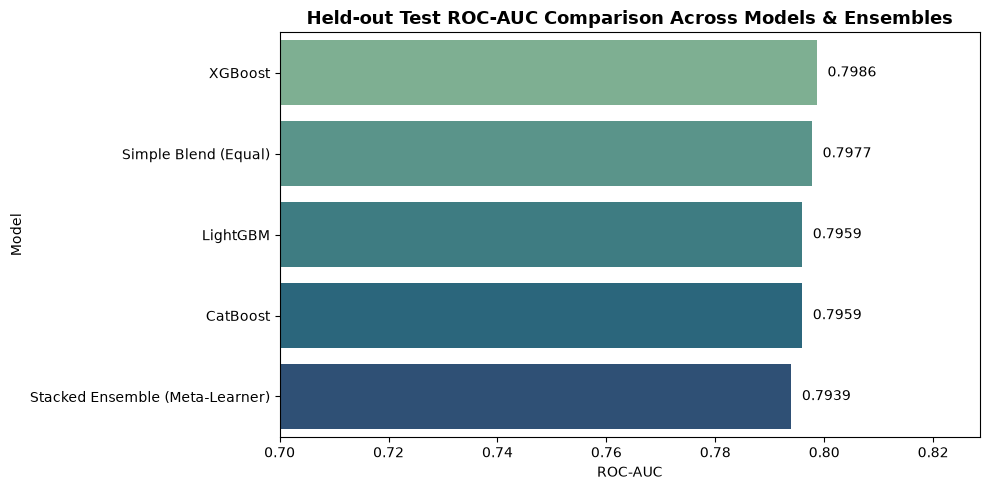

In [29]:
# Generate Held-out Test Predictions
test_probs = {}
for name in model_names:
    test_probs[name] = test_fold_preds[name]

# Ensembles on Held-out Test Set
X_test_meta = np.column_stack([test_probs[m] for m in model_names])
test_probs["Simple Blend (Equal)"] = np.mean(X_test_meta, axis=1)
test_probs["Stacked Ensemble (Meta-Learner)"] = meta_learner.predict_proba(X_test_meta)[:, 1]

# Compute performance metrics for each model and blend
comparison_records = []
for name, probs in test_probs.items():
    preds = (probs >= 0.50).astype(int)
    comparison_records.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4),
        "PR-AUC": round(average_precision_score(y_test, probs), 4),
        "F1 Score": round(f1_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "Log Loss": round(log_loss(y_test, probs), 4)
    })

comparison_df = pd.DataFrame(comparison_records).sort_values(by="ROC-AUC", ascending=False)
print("=" * 65)
print("       HELD-OUT TEST SET PERFORMANCE COMPARISON")
print("=" * 65)
try:
    from IPython.display import display
    display(comparison_df)
except ImportError:
    print(comparison_df.to_string(index=False))

# Visualization: Model Comparison Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(data=comparison_df, x="ROC-AUC", y="Model", hue="Model", palette="crest", legend=False)
plt.title("Held-out Test ROC-AUC Comparison Across Models & Ensembles", fontsize=13, weight='bold')
plt.xlim(0.70, max(comparison_df['ROC-AUC']) + 0.03)
for idx, row in comparison_df.reset_index(drop=True).iterrows():
    plt.text(row['ROC-AUC'] + 0.002, idx, f"{row['ROC-AUC']:.4f}", va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 10. Operational Decision Threshold Calibration for Optimal Blend

In supply chain operations, missing a late delivery (**False Negative**) triggers SLA penalties and customer dissatisfaction.
We calibrate the decision cutoff threshold on the **Optimal Blended Ensemble** to maximize operational Recall.

In [ ]:
import joblib
from pathlib import Path

# Resolve path whether running inside notebook/ folder or project root
if Path("backend/model_artifacts").exists() or Path("backend").exists():
    artifacts_dir = Path("backend/model_artifacts")
elif Path("../backend/model_artifacts").exists() or Path("../backend").exists():
    artifacts_dir = Path("../backend/model_artifacts")
else:
    artifacts_dir = Path("backend/model_artifacts")

artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Base models
joblib.dump(lgb_clf, artifacts_dir / "lgb_model.joblib")
joblib.dump(cat_clf, artifacts_dir / "cat_model.joblib")# 5-Fold GroupKFold OOF Stacking Engine
model_names = ["LightGBM", "CatBoost", "XGBoost"]
oof_preds = {name: np.zeros(len(x_train_enc)) for name in model_names}
test_fold_preds = {name: np.zeros(len(x_test_enc)) for name in model_names}

cat_indices = [x_train_cat.columns.get_loc(col) for col in categorical_features]

print(f"Executing 5-Fold GroupKFold Out-of-Fold Stacking across {N_SPLITS} folds...")

for fold, (f_train, f_val) in enumerate(cv_folds):
    print(f"\n--- Training Fold {fold + 1}/{N_SPLITS} ---")
    
    # 1. LightGBM (Tuned)
    lgb_clf = LGBMClassifier(**best_lgb_params)
    lgb_clf.fit(x_train_enc.iloc[f_train], y_train.iloc[f_train])
    val_p_lgb = lgb_clf.predict_proba(x_train_enc.iloc[f_val])[:, 1]
    oof_preds["LightGBM"][f_val] = val_p_lgb
    test_fold_preds["LightGBM"] += lgb_clf.predict_proba(x_test_enc)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} LightGBM ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_lgb):.4f}")
    
    # 2. CatBoost (with native categorical features)
    cat_clf = CatBoostClassifier(**best_cat_params, cat_features=cat_indices)
    cat_clf.fit(x_train_cat.iloc[f_train], y_train.iloc[f_train])
    val_p_cat = cat_clf.predict_proba(x_train_cat.iloc[f_val])[:, 1]
    oof_preds["CatBoost"][f_val] = val_p_cat
    test_fold_preds["CatBoost"] += cat_clf.predict_proba(x_test_cat)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} CatBoost ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_cat):.4f}")
    
    # 3. XGBoost
    xgb_clf = XGBClassifier(**best_xgb_params)
    xgb_clf.fit(x_train_enc.iloc[f_train], y_train.iloc[f_train])
    val_p_xgb = xgb_clf.predict_proba(x_train_enc.iloc[f_val])[:, 1]
    oof_preds["XGBoost"][f_val] = val_p_xgb
    test_fold_preds["XGBoost"] += xgb_clf.predict_proba(x_test_enc)[:, 1] / N_SPLITS
    print(f"  Fold {fold + 1} XGBoost  ROC-AUC: {roc_auc_score(y_train.iloc[f_val], val_p_xgb):.4f}")

print("\n" + "=" * 50)
print("     OUT-OF-FOLD (OOF) MODEL PERFORMANCE")
print("=" * 50)
for name in model_names:
    auc = roc_auc_score(y_train, oof_preds[name])
    loss = log_loss(y_train, oof_preds[name])
    print(f"  {name:12s} | OOF ROC-AUC: {auc:.4f} | OOF Log Loss: {loss:.4f}")

# Train Meta-Learner on Out-of-Fold Probability Matrix
X_oof = np.column_stack([oof_preds[m] for m in model_names])
meta_learner = LogisticRegressionCV(cv=5, scoring='roc_auc', max_iter=1000, random_state=42)
meta_learner.fit(X_oof, y_train)

print(f"\nMeta-Learner Coefficients (Stacking Weights):")
for name, coef in zip(model_names, meta_learner.coef_[0]):
    print(f"  {name:12s}: {coef:.4f}")
joblib.dump(xgb_clf, artifacts_dir / "xgb_model.joblib")

# 2. Stacked Meta-Learner
joblib.dump(meta_learner, artifacts_dir / "meta_learner.joblib")

# 3. Categorical Encoder (handles ord_encoder name from Cell 15)
saved_encoder = ord_encoder if 'ord_encoder' in locals() else encoder
joblib.dump(saved_encoder, artifacts_dir / "ordinal_encoder.joblib")

# 4. Numerical Training Medians (for missing values in production)
medians_dict = {col: float(x_train_raw[col].median()) for col in numerical_features if col in x_train_raw.columns}
joblib.dump(medians_dict, artifacts_dir / "numerical_medians.joblib")

print(f"✅ All model artifacts exported successfully to {artifacts_dir.resolve()}!")


✅ All model artifacts exported successfully to /run/media/haseeb-ahmad/Personal Data/DelaySense/backend/model_artifacts!
